<a href="https://colab.research.google.com/github/Ripazha05/Probabilitas-dan-Statistika-Projek-kelompok/blob/main/Probabilitas_Dan_Statistika.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# 1. Memuat Dataset dari file Excel
excel_path = '3TIE_09_StudentSpending (1).xlsx'
df = pd.read_excel(excel_path, sheet_name='student_spending')

print('--- 1. INFORMASI AWAL DATASET ---')
print(f'Total Baris (Responden): {df.shape[0]}')
print(f'Total Kolom Awal: {df.shape[1]}\n')

# 2. Pengecekan Missing Value (Nilai Kosong)
print('--- 2. PENGECEKAN MISSING VALUE ---')
missing_values = df.isnull().sum()
if missing_values.sum() == 0:
  print(
      'Status: Aman! Tidak ada missing value (data kosong) pada seluruh'
      ' kolom.'
  )
else:
  print(missing_values[missing_values > 0])
print()

# 3. Seleksi & Penyiapan Variabel Sesuai Judul Penelitian
# Daftar kolom seluruh komponen pengeluaran bulanan
expenditure_cols = [
    'housing',
    'food',
    'transportation',
    'books_supplies',
    'entertainment',
    'personal_care',
    'technology',
    'health_wellness',
    'miscellaneous',
]

# 4. Feature Engineering: Membuat Kolom Total Pengeluaran (Variabel Dependen Y)
df['total_pengeluaran'] = df[expenditure_cols].sum(axis=1)

print('--- 3. CONTOH HASIL PENYIAPAN VARIABEL UTAMA ---')
print(
    df[
        [
            'id',
            'housing',
            'food',
            'total_pengeluaran',
        ]
    ].head(5)
)
print()

# 5. Memeriksa Tipe Data Variabel Utama
print('--- 4. TIPE DATA VARIABEL UTAMA ---')
print(df[['housing', 'food', 'total_pengeluaran']].dtypes)

--- 1. INFORMASI AWAL DATASET ---
Total Baris (Responden): 1000
Total Kolom Awal: 18

--- 2. PENGECEKAN MISSING VALUE ---
Status: Aman! Tidak ada missing value (data kosong) pada seluruh kolom.

--- 3. CONTOH HASIL PENYIAPAN VARIABEL UTAMA ---
   id  housing  food  total_pengeluaran
0   0      709   296               1768
1   1      557   365               1848
2   2      666   220               1759
3   3      652   289               1730
4   4      825   372               1941

--- 4. TIPE DATA VARIABEL UTAMA ---
housing              int64
food                 int64
total_pengeluaran    int64
dtype: object


--- TABEL STATISTIKA DESKRIPTIF LENGKAP ---
                       housing         food  total_pengeluaran
Jumlah Data (n)    1000.000000  1000.000000        1000.000000
Mean (Rata-rata)    696.006000   252.642000        1795.083000
Median (Q2)         704.500000   255.000000        1784.000000
Std. Deviasi        171.218620    86.949606         238.497890
Varians           29315.815780  7560.234070       56881.243354
Q1 (25%)            538.750000   175.000000        1622.000000
Q3 (75%)            837.250000   330.000000        1968.500000
Min                 401.000000   100.000000        1055.000000
Max                1000.000000   400.000000        2453.000000
Skewness             -0.052407    -0.047806          -0.001092
Kurtosis             -1.203298    -1.204757          -0.349747 



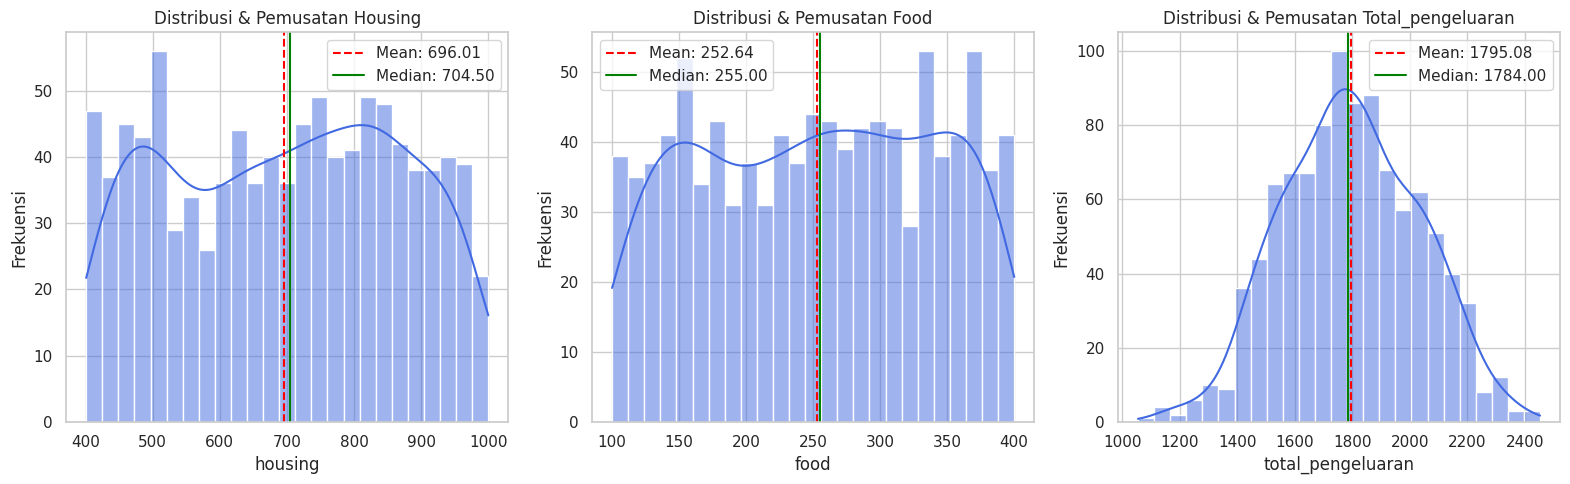

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Memuat Data & Menyiapkan Variabel Total Pengeluaran
excel_path = '3TIE_09_StudentSpending (1).xlsx'
df = pd.read_excel(excel_path, sheet_name='student_spending')

expenditure_cols = [
    'housing',
    'food',
    'transportation',
    'books_supplies',
    'entertainment',
    'personal_care',
    'technology',
    'health_wellness',
    'miscellaneous',
]
df['total_pengeluaran'] = df[expenditure_cols].sum(axis=1)

# 2. Menghitung Metrik Deskriptif Lengkap
vars_desc = ['housing', 'food', 'total_pengeluaran']

summary_table = pd.DataFrame(
    {
        'Jumlah Data (n)': df[vars_desc].count(),
        'Mean (Rata-rata)': df[vars_desc].mean(),
        'Median (Q2)': df[vars_desc].median(),
        'Std. Deviasi': df[vars_desc].std(),
        'Varians': df[vars_desc].var(),
        'Q1 (25%)': df[vars_desc].quantile(0.25),
        'Q3 (75%)': df[vars_desc].quantile(0.75),
        'Min': df[vars_desc].min(),
        'Max': df[vars_desc].max(),
        'Skewness': df[vars_desc].skew(),
        'Kurtosis': df[vars_desc].kurtosis(),
    }
)

print('--- TABEL STATISTIKA DESKRIPTIF LENGKAP ---')
print(summary_table.T.to_string(), '\n')

# 3. Visualisasi Grafik yang Lebih Informatif (Histogram + KDE + Garis Mean & Median)
sns.set_theme(style='whitegrid')
plt.figure(figsize=(16, 5))

for i, col in enumerate(vars_desc, 1):
  plt.subplot(1, 3, i)
  sns.histplot(df[col], kde=True, color='royalblue', bins=25)

  # Menambahkan garis vertikal untuk Mean dan Median
  mean_val = df[col].mean()
  median_val = df[col].median()
  plt.axvline(
      mean_val, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.2f}'
  )
  plt.axvline(
      median_val,
      color='green',
      linestyle='-',
      linewidth=1.5,
      label=f'Median: {median_val:.2f}',
  )

  plt.title(f'Distribusi & Pemusatan {col.capitalize()}')
  plt.xlabel(col)
  plt.ylabel('Frekuensi')
  plt.legend()

plt.tight_layout()
plt.show()

--- MATRIKS KORELASI PEARSON ---
                    housing      food  total_pengeluaran
housing            1.000000 -0.038335           0.701750
food              -0.038335  1.000000           0.376564
total_pengeluaran  0.701750  0.376564           1.000000 



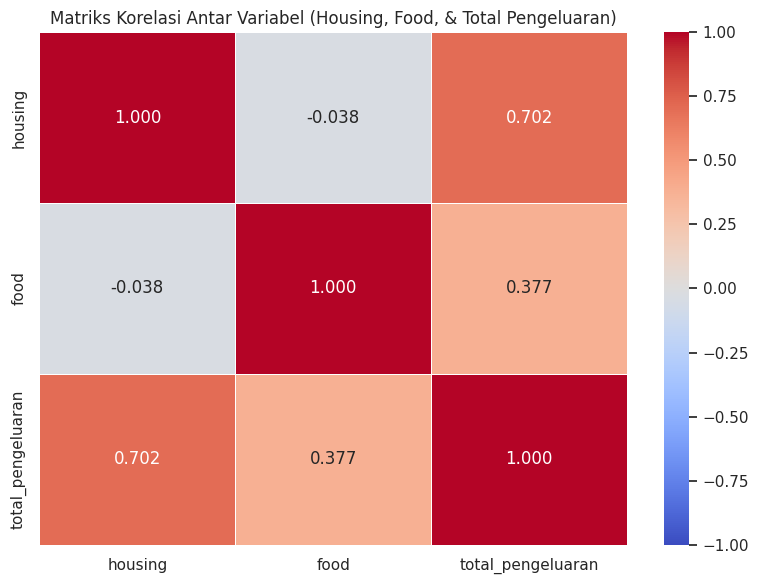

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Memuat Data & Menyiapkan Variabel Total Pengeluaran
excel_path = '3TIE_09_StudentSpending (1).xlsx'
df = pd.read_excel(excel_path, sheet_name='student_spending')

expenditure_cols = [
    'housing',
    'food',
    'transportation',
    'books_supplies',
    'entertainment',
    'personal_care',
    'technology',
    'health_wellness',
    'miscellaneous',
]
df['total_pengeluaran'] = df[expenditure_cols].sum(axis=1)

# 2. Memilih variabel untuk korelasi
vars_corr = ['housing', 'food', 'total_pengeluaran']
correlation_matrix = df[vars_corr].corr(method='pearson')

print('--- MATRIKS KORELASI PEARSON ---')
print(correlation_matrix.to_string(), '\n')

# 3. Visualisasi Korelasi dengan Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)
plt.title(
    'Matriks Korelasi Antar Variabel (Housing, Food, & Total Pengeluaran)'
)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import statsmodels.api as sm

# 1. Memuat Data & Menyiapkan Variabel Total Pengeluaran
excel_path = '3TIE_09_StudentSpending (1).xlsx'
df = pd.read_excel(excel_path, sheet_name='student_spending')

expenditure_cols = [
    'housing',
    'food',
    'transportation',
    'books_supplies',
    'entertainment',
    'personal_care',
    'technology',
    'health_wellness',
    'miscellaneous',
]
df['total_pengeluaran'] = df[expenditure_cols].sum(axis=1)

# 2. Menentukan Variabel X (Independen) dan Y (Dependen)
X = df[['housing', 'food']]
X = sm.add_constant(X)  # Menambahkan konstanta (intercept / beta_0)
y = df['total_pengeluaran']

# 3. Membangun Model OLS (Ordinary Least Squares)
regression_model = sm.OLS(y, X).fit()

# 4. Menampilkan Ringkasan Hasil Regresi
print('--- RINGKASAN HASIL REGRESI LINIER BERGANDA ---')
print(regression_model.summary())

--- RINGKASAN HASIL REGRESI LINIER BERGANDA ---
                            OLS Regression Results                            
Dep. Variable:      total_pengeluaran   R-squared:                       0.655
Model:                            OLS   Adj. R-squared:                  0.655
Method:                 Least Squares   F-statistic:                     948.4
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          2.01e-231
Time:                        17:13:45   Log-Likelihood:                -6360.0
No. Observations:                1000   AIC:                         1.273e+04
Df Residuals:                     997   BIC:                         1.274e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
cons

--- 1. UJI MULTIKOLINEARITAS (VIF) ---
Variabel  Nilai VIF
 housing   1.001472
    food   1.001472
Kriteria: Jika VIF < 10, maka tidak terjadi multikolinearitas.

--- 2. UJI NORMALITAS RESIDUAL (Jarque-Bera) ---
Nilai Statistik JB: 1.5834
P-value: 0.4531
Kesimpulan: Residual berdistribusi normal (Asumsi terpenuhi).

--- 3. UJI HETEROSKEDASTISITAS (Breusch-Pagan) ---
Lagrange Multiplier Statistic: 4.9214
P-value: 0.0854
Kesimpulan: Tidak terjadi heteroskedastisitas / varian konstan (Asumsi terpenuhi).



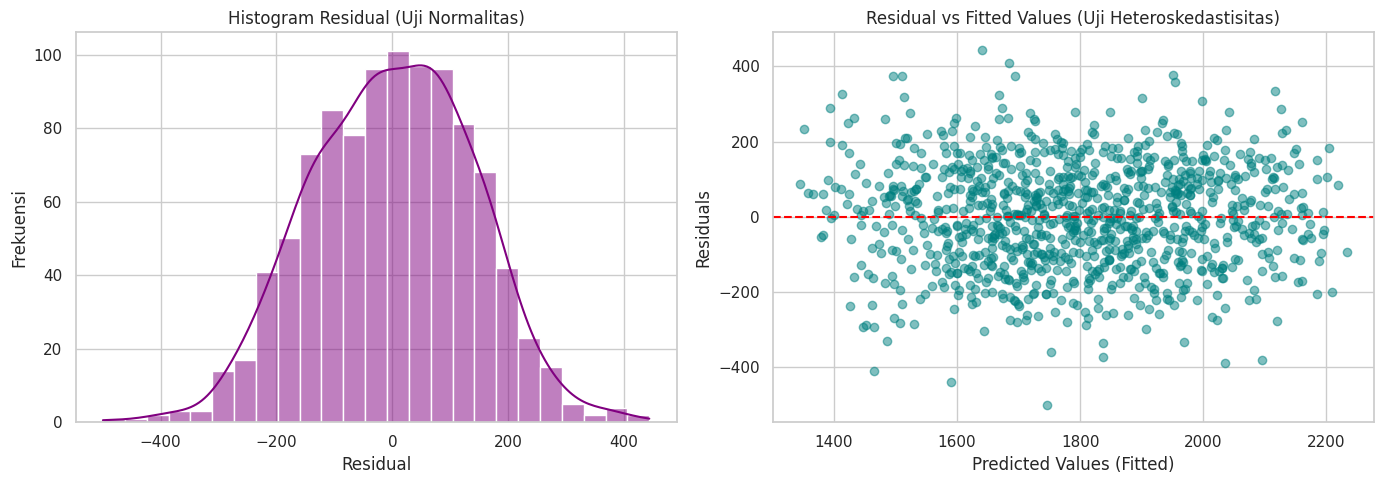

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Memuat Data & Menyiapkan Variabel
excel_path = '3TIE_09_StudentSpending (1).xlsx'
df = pd.read_excel(excel_path, sheet_name='student_spending')

expenditure_cols = [
    'housing',
    'food',
    'transportation',
    'books_supplies',
    'entertainment',
    'personal_care',
    'technology',
    'health_wellness',
    'miscellaneous',
]
df['total_pengeluaran'] = df[expenditure_cols].sum(axis=1)

X = df[['housing', 'food']]
X = sm.add_constant(X)
y = df['total_pengeluaran']

model = sm.OLS(y, X).fit()

# ==========================================
# A. UJI MULTIKOLINEARITAS (VIF)
# ==========================================
vif_data = pd.DataFrame()
vif_data['Variabel'] = X.columns[1:]  # Mengabaikan konstanta
vif_data['Nilai VIF'] = [
    variance_inflation_factor(X.values, i) for i in range(1, len(X.columns))
]
print('--- 1. UJI MULTIKOLINEARITAS (VIF) ---')
print(vif_data.to_string(index=False))
print(
    'Kriteria: Jika VIF < 10, maka tidak terjadi multikolinearitas.\n'
)

# ==========================================
# B. UJI NORMALITAS RESIDUAL (Jarque-Bera)
# ==========================================
jb_stat, jb_pval = stats.jarque_bera(model.resid)
print('--- 2. UJI NORMALITAS RESIDUAL (Jarque-Bera) ---')
print(f'Nilai Statistik JB: {jb_stat:.4f}')
print(f'P-value: {jb_pval:.4f}')
if jb_pval > 0.05:
  print('Kesimpulan: Residual berdistribusi normal (Asumsi terpenuhi).\n')
else:
  print('Kesimpulan: Residual tidak berdistribusi normal.\n')

# ==========================================
# C. UJI HETEROSKEDASTISITAS (Breusch-Pagan)
# ==========================================
bp_test = het_breuschpagan(model.resid, model.model.exog)
bp_pval = bp_test[1]
print('--- 3. UJI HETEROSKEDASTISITAS (Breusch-Pagan) ---')
print(f'Lagrange Multiplier Statistic: {bp_test[0]:.4f}')
print(f'P-value: {bp_pval:.4f}')
if bp_pval > 0.05:
  print(
      'Kesimpulan: Tidak terjadi heteroskedastisitas / varian konstan (Asumsi'
      ' terpenuhi).\n'
  )
else:
  print('Kesimpulan: Terjadi heteroskedastisitas.\n')

# ==========================================
# D. VISUALISASI DIAGNOSTIK RESIDUAL
# ==========================================
sns.set_theme(style='whitegrid')
plt.figure(figsize=(14, 5))

# Plot 1: Histogram Residual & Garis Normal
plt.subplot(1, 2, 1)
sns.histplot(model.resid, kde=True, color='purple', bins=25)
plt.title('Histogram Residual (Uji Normalitas)')
plt.xlabel('Residual')
plt.ylabel('Frekuensi')

# Plot 2: Scatter Plot Fitted Values vs Residual (Uji Heteroskedastisitas)
plt.subplot(1, 2, 2)
plt.scatter(model.fittedvalues, model.resid, alpha=0.5, color='teal')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title('Residual vs Fitted Values (Uji Heteroskedastisitas)')
plt.xlabel('Predicted Values (Fitted)')
plt.ylabel('Residuals')

plt.tight_layout()
plt.show()